In [1]:
!pip -q install scikit-learn pandas numpy matplotlib seaborn joblib

import sklearn
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import time
import platform

print("CrossModel BenchLab initialized successfully!")
print("Scikit-learn version:", sklearn.__version__)
print("Python version:", platform.python_version())


CrossModel BenchLab initialized successfully!
Scikit-learn version: 1.6.1
Python version: 3.13.16


##Dataset
**Source:** UCI Machine Learning Repository  
https://archive.ics.uci.edu/dataset/17/breast+cancer+wisconsin+diagnostic

In [2]:

from sklearn.datasets import load_breast_cancer

dataset = load_breast_cancer()

X = pd.DataFrame(
    dataset.data,
    columns=dataset.feature_names
)

y = pd.Series(
    dataset.target,
    name="target"
)

print("Total samples:", X.shape[0])
print("Total features:", X.shape[1])

print("\nClass distribution:")
print(y.value_counts().sort_index())

display(X.head())


Total samples: 569
Total features: 30

Class distribution:
target
0    212
1    357
Name: count, dtype: int64


,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst radius,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,25.38,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,24.99,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,...,23.57,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,...,14.91,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,...,22.54,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678


## Data Partitioning

The dataset is divided into development and independent testing partitions using an 80/20 stratified split.

In [3]:

from sklearn.model_selection import train_test_split

SEED = 42

X_dev, X_test, y_dev, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=SEED,
    stratify=y
)

print("Development samples:", len(X_dev))
print("Test samples:", len(X_test))

print("\nDevelopment class distribution:")
print(y_dev.value_counts().sort_index())

print("\nTest class distribution:")
print(y_test.value_counts().sort_index())

assert set(X_dev.index).isdisjoint(set(X_test.index))

print("\nPASS: No overlap between partitions")


Development samples: 455
Test samples: 114

Development class distribution:
target
0    170
1    285
Name: count, dtype: int64

Test class distribution:
target
0    42
1    72
Name: count, dtype: int64

PASS: No overlap between partitions


## Machine Learning Models Train
*   80/20 stratified development/test split
*   3 × 5 outer stratified folds; 3 inner folds
*   10 candidate configurations per inner search
*   Model-specific leakage-safe pipelines

### Logistic Regression
### Random Forest
### Support Vector Machine




In [4]:

from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.model_selection import ParameterGrid

models = {
    "Logistic Regression": Pipeline([
        ("scaler", StandardScaler()),
        ("model", LogisticRegression(
            max_iter=3000,
            random_state=SEED
        ))
    ]),

    "Random Forest": Pipeline([
        ("model", RandomForestClassifier(
            random_state=SEED,
            n_jobs=1
        ))
    ]),

    "SVM": Pipeline([
        ("scaler", StandardScaler()),
        ("model", SVC(
            probability=False,
            random_state=SEED
        ))
    ])
}

param_grids = {
    "Logistic Regression": {
        "model__C": [
            0.001, 0.005, 0.01, 0.05, 0.1,
            0.5, 1, 5, 10, 50
        ]
    },

    "Random Forest": {
        "model__n_estimators": [100, 200],
        "model__max_depth": [None, 3, 5, 10, 20]
    },

    "SVM": {
        "model__C": [0.01, 0.1, 1, 10, 100],
        "model__gamma": ["scale", "auto"]
    }
}

for name in models:
    count = len(list(ParameterGrid(param_grids[name])))
    print(f"{name}: {count} configurations")
    assert count == 10

print("\nAll three models are ready!")


Logistic Regression: 10 configurations
Random Forest: 10 configurations
SVM: 10 configurations

All three models are ready!


##Nested Cross Validatio

In [5]:

from sklearn.model_selection import (
    RepeatedStratifiedKFold,
    StratifiedKFold,
    GridSearchCV
)
from sklearn.base import clone
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)

import pandas as pd
import numpy as np
import hashlib
import pickle
import json
import time

# Outer cross-validation protocol
outer_cv = RepeatedStratifiedKFold(
    n_splits=5,
    n_repeats=3,
    random_state=SEED
)

# Store identical partitions for all models
outer_splits = list(
    outer_cv.split(X_dev, y_dev)
)

results = []
audit_records = []
best_configs = []

def index_signature(indices):
    values = sorted(map(int, indices))
    raw = json.dumps(values).encode("utf-8")
    return hashlib.sha256(raw).hexdigest()


for model_name, model in models.items():

    print(f"\nStarting Model: {model_name}", flush=True)

    for fold_id, (train_idx, val_idx) in enumerate(
        outer_splits, start=1
    ):

        X_train = X_dev.iloc[train_idx]
        X_val = X_dev.iloc[val_idx]

        y_train = y_dev.iloc[train_idx]
        y_val = y_dev.iloc[val_idx]

        # Inner 3-fold cross-validation
        inner_cv = StratifiedKFold(
            n_splits=3,
            shuffle=True,
            random_state=SEED + fold_id
        )

        search = GridSearchCV(
            estimator=clone(model),
            param_grid=param_grids[model_name],
            scoring="f1",
            cv=inner_cv,
            n_jobs=-1,
            refit=True,
            error_score="raise"
        )

        start_time = time.perf_counter()

        search.fit(X_train, y_train)

        training_time = (
            time.perf_counter() - start_time
        )

        best_model = search.best_estimator_

        inference_start = time.perf_counter()

        y_pred = best_model.predict(X_val)

        inference_time = (
            time.perf_counter() - inference_start
        )

        if hasattr(best_model, "decision_function"):
            y_score = best_model.decision_function(X_val)
        else:
            y_score = best_model.predict_proba(X_val)[:, 1]

        scores = {
            "model": model_name,
            "fold": fold_id,
            "repeat": (fold_id - 1) // 5 + 1,
            "accuracy": accuracy_score(y_val, y_pred),
            "precision": precision_score(
                y_val, y_pred, zero_division=0
            ),
            "recall": recall_score(
                y_val, y_pred, zero_division=0
            ),
            "f1": f1_score(
                y_val, y_pred, zero_division=0
            ),
            "roc_auc": roc_auc_score(
                y_val, y_score
            ),
            "train_seconds": training_time,
            "inference_ms_per_sample": (
                inference_time * 1000 / len(X_val)
            ),
            "model_size_kb": (
                len(pickle.dumps(best_model)) / 1024
            )
        }

        results.append(scores)

        best_configs.append({
            "model": model_name,
            "fold": fold_id,
            "parameters": search.best_params_,
            "inner_f1": search.best_score_
        })

        audit_records.append({
            "model": model_name,
            "fold": fold_id,
            "train_signature": index_signature(train_idx),
            "val_signature": index_signature(val_idx),
            "preprocessing_in_pipeline": isinstance(
                best_model, Pipeline
            ),
            "tuning_candidates": len(
                search.cv_results_["params"]
            ),
            "inner_folds": search.n_splits_,
            "seed": SEED + fold_id,
            "metric": search.scoring,
            "dataset": "Breast Cancer Wisconsin Diagnostic",
            "positive_class": 1
        })

        print(
            f"Fold {fold_id:02d}/15 | "
            f"F1: {scores['f1']:.4f} | "
            f"Time: {training_time:.2f}s",
            flush=True
        )


# Convert results into DataFrames
results_df = pd.DataFrame(results)
audit_df = pd.DataFrame(audit_records)
configs_df = pd.DataFrame(best_configs)

print("\nNested Cross Validation Completed!")
print("Total Evaluations:", len(results_df))

assert len(results_df) == 45
assert len(audit_df) == 45

display(results_df.head())



Starting Model: Logistic Regression
Fold 01/15 | F1: 0.9744 | Time: 5.19s
Fold 02/15 | F1: 0.9825 | Time: 0.79s
Fold 03/15 | F1: 0.9825 | Time: 0.82s
Fold 04/15 | F1: 0.9913 | Time: 1.14s
Fold 05/15 | F1: 0.9735 | Time: 0.78s
Fold 06/15 | F1: 0.9744 | Time: 0.76s
Fold 07/15 | F1: 0.9739 | Time: 0.83s
Fold 08/15 | F1: 0.9913 | Time: 1.19s
Fold 09/15 | F1: 0.9913 | Time: 1.30s
Fold 10/15 | F1: 0.9744 | Time: 1.42s
Fold 11/15 | F1: 0.9828 | Time: 0.76s
Fold 12/15 | F1: 0.9912 | Time: 0.77s
Fold 13/15 | F1: 0.9744 | Time: 0.81s
Fold 14/15 | F1: 0.9912 | Time: 0.82s
Fold 15/15 | F1: 0.9744 | Time: 0.63s

Starting Model: Random Forest
Fold 01/15 | F1: 0.9735 | Time: 14.93s
Fold 02/15 | F1: 0.9643 | Time: 9.87s
Fold 03/15 | F1: 0.9464 | Time: 8.47s
Fold 04/15 | F1: 0.9744 | Time: 10.15s
Fold 05/15 | F1: 0.9825 | Time: 10.08s
Fold 06/15 | F1: 0.9565 | Time: 8.78s
Fold 07/15 | F1: 0.9828 | Time: 9.24s
Fold 08/15 | F1: 0.9739 | Time: 9.84s
Fold 09/15 | F1: 0.9655 | Time: 8.64s
Fold 10/15 | F1: 

,model,fold,repeat,accuracy,precision,recall,f1,roc_auc,train_seconds,inference_ms_per_sample,model_size_kb
0,Logistic Regression,1,1,0.967033,0.950000,1.000000,0.974359,0.986584,5.185608,0.030660,2.615234
1,Logistic Regression,2,1,0.978022,0.982456,0.982456,0.982456,0.998452,0.785257,0.098978,2.615234
2,Logistic Regression,3,1,0.978022,0.982456,0.982456,0.982456,0.996904,0.816285,0.094999,2.608398
3,Logistic Regression,4,1,0.989011,0.982759,1.000000,0.991304,0.998968,1.142537,0.052497,2.608398
4,Logistic Regression,5,1,0.967033,0.982143,0.964912,0.973451,0.997936,0.784568,0.027533,2.615234


## Model Performance Comparison

=== MODEL COMPARISON ===


,mean_f1,std_f1,accuracy,precision,recall,roc_auc,training_seconds,inference_ms,model_size_kb
model,,,,,,,,,
Logistic Regression,0.9815,0.0078,0.9766,0.9718,0.9918,0.9956,1.2014,0.0645,2.6139
SVM,0.9749,0.0087,0.9685,0.9737,0.9766,0.9948,0.3813,0.0274,23.3958
Random Forest,0.9685,0.0111,0.9604,0.9645,0.9731,0.9898,9.9750,0.1489,388.0410


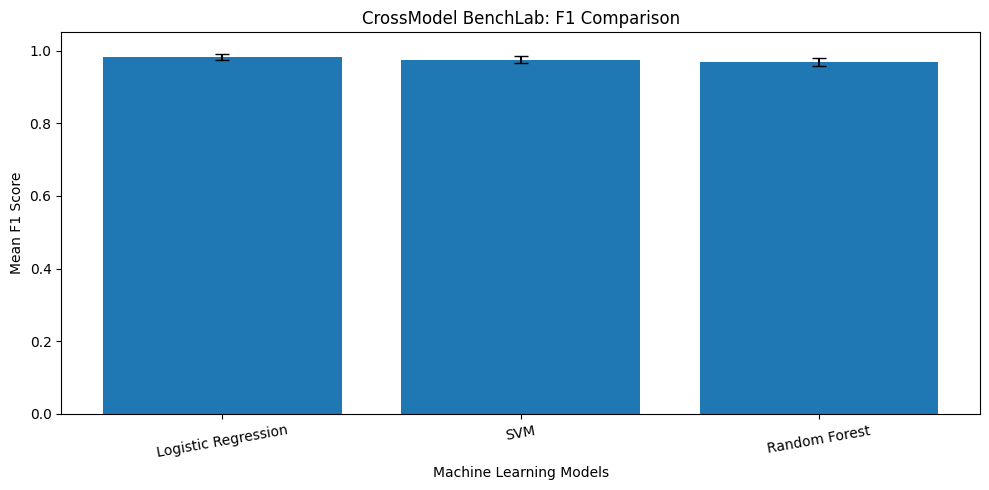


Files saved successfully!
benchmark_summary.csv
fold_results.csv
selected_hyperparameters.csv
model_comparison.png


In [6]:

import matplotlib.pyplot as plt

summary_df = (
    results_df.groupby("model")
    .agg(
        mean_f1=("f1", "mean"),
        std_f1=("f1", "std"),
        accuracy=("accuracy", "mean"),
        precision=("precision", "mean"),
        recall=("recall", "mean"),
        roc_auc=("roc_auc", "mean"),
        training_seconds=("train_seconds", "mean"),
        inference_ms=("inference_ms_per_sample", "mean"),
        model_size_kb=("model_size_kb", "mean")
    )
    .sort_values(
        "mean_f1",
        ascending=False
    )
)

print("=== MODEL COMPARISON ===")
display(summary_df.round(4))

# F1 comparison chart
plt.figure(figsize=(10, 5))

plt.bar(
    summary_df.index,
    summary_df["mean_f1"],
    yerr=summary_df["std_f1"],
    capsize=5
)

plt.title("CrossModel BenchLab: F1 Comparison")
plt.xlabel("Machine Learning Models")
plt.ylabel("Mean F1 Score")
plt.ylim(0, 1.05)
plt.xticks(rotation=10)
plt.tight_layout()

plt.savefig(
    "model_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# Save actual results
summary_df.to_csv("benchmark_summary.csv")
results_df.to_csv(
    "fold_results.csv",
    index=False
)
configs_df.to_csv(
    "selected_hyperparameters.csv",
    index=False
)

print("\nFiles saved successfully!")
print("benchmark_summary.csv")
print("fold_results.csv")
print("selected_hyperparameters.csv")
print("model_comparison.png")


## Automated Benchmark Fairness Audit


In [7]:

import platform
import sklearn

def audit_check(condition, available=True):
    if not available:
        return "NOT VERIFIABLE"

    return "PASS" if condition else "FLAGGED"


audit_report = []

expected_models = set(models.keys())

for fold_id in range(1, 16):

    records = audit_df[
        audit_df["fold"] == fold_id
    ].copy()

    complete = (
        len(records) == 3
        and set(records["model"]) == expected_models
    )

    partition_available = (
        complete
        and records[
            ["train_signature", "val_signature"]
        ].notna().all().all()
    )

    partition_ok = (
        partition_available
        and records["train_signature"].nunique() == 1
        and records["val_signature"].nunique() == 1
    )

    preprocessing_available = (
        complete
        and records[
            "preprocessing_in_pipeline"
        ].notna().all()
    )

    preprocessing_ok = (
        preprocessing_available
        and records[
            "preprocessing_in_pipeline"
        ].eq(True).all()
    )

    tuning_available = (
        complete
        and records[
            ["tuning_candidates", "inner_folds"]
        ].notna().all().all()
    )

    tuning_ok = (
        tuning_available
        and records["tuning_candidates"].eq(10).all()
        and records["inner_folds"].eq(3).all()
    )

    seed_available = (
        complete
        and records["seed"].notna().all()
    )

    seed_ok = (
        seed_available
        and records["seed"].nunique() == 1
        and records["seed"].iloc[0] == SEED + fold_id
    )

    metric_available = (
        complete
        and records[
            ["metric", "positive_class", "dataset"]
        ].notna().all().all()
    )

    metric_ok = (
        metric_available
        and records["metric"].eq("f1").all()
        and records["positive_class"].eq(1).all()
        and records["dataset"].nunique() == 1
    )

    checks = {
        "Partition Integrity": audit_check(
            partition_ok, partition_available
        ),
        "Preprocessing Metadata": audit_check(
            preprocessing_ok, preprocessing_available
        ),
        "Tuning Budget": audit_check(
            tuning_ok, tuning_available
        ),
        "Random Seed": audit_check(
            seed_ok, seed_available
        ),
        "Metric Consistency": audit_check(
            metric_ok, metric_available
        ),
        "Environment Metadata": audit_check(
            bool(platform.python_version())
            and bool(sklearn.__version__)
        )
    }

    for check_name, status in checks.items():
        audit_report.append({
            "fold": fold_id,
            "check": check_name,
            "status": status
        })


audit_report_df = pd.DataFrame(audit_report)

print("=== BENCHMARK FAIRNESS AUDIT ===")

display(
    audit_report_df.pivot(
        index="fold",
        columns="check",
        values="status"
    )
)

print("\nAudit Status Summary:")
print(audit_report_df["status"].value_counts())

audit_report_df.to_csv(
    "fairness_audit_report.csv",
    index=False
)

print("\nEnvironment:")
print("Python:", platform.python_version())
print("Scikit-learn:", sklearn.__version__)

assert len(audit_report_df) == 90

print("\nAudit report saved successfully!")


=== BENCHMARK FAIRNESS AUDIT ===


check,Environment Metadata,Metric Consistency,Partition Integrity,Preprocessing Metadata,Random Seed,Tuning Budget
fold,,,,,,
1,PASS,PASS,PASS,PASS,PASS,PASS
2,PASS,PASS,PASS,PASS,PASS,PASS
3,PASS,PASS,PASS,PASS,PASS,PASS
4,PASS,PASS,PASS,PASS,PASS,PASS
5,PASS,PASS,PASS,PASS,PASS,PASS
6,PASS,PASS,PASS,PASS,PASS,PASS
7,PASS,PASS,PASS,PASS,PASS,PASS
8,PASS,PASS,PASS,PASS,PASS,PASS
9,PASS,PASS,PASS,PASS,PASS,PASS



Audit Status Summary:
status
PASS    90
Name: count, dtype: int64

Environment:
Python: 3.13.16
Scikit-learn: 1.6.1

Audit report saved successfully!



## Controlled Protocol Violation Study

### Research Objectives

RQ1: Evaluate whether automated audit rules identify intentionally introduced protocol inconsistencies.

RQ2: Examine whether these inconsistencies change measured model performance or model rankings.

### Experimental Design

The first five outer folds from the controlled nested cross-validation experiment are used as the reference.

Three scenarios are compared:

1. Controlled Reference: All models use the original benchmark protocol.
2. Unequal Tuning: The SVM search budget is deliberately reduced from 10 to 2 configurations.
3. Preprocessing Leakage: The SVM scaler is deliberately fitted outside the permitted training-fold boundary.

The other two model families retain their controlled reference results.

All violations are limited to development data. The independent holdout test set remains untouched.

These are diagnostic experiments, not recommended model-training procedures.


In [8]:

import pandas as pd
import numpy as np
import time

from sklearn.base import clone
from sklearn.model_selection import (
    StratifiedKFold,
    GridSearchCV
)
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)


assert len(results_df) == 45
assert len(audit_df) == 45
assert len(outer_splits) == 15


experiment_folds = outer_splits[:5]

reference_df = results_df[
    results_df["fold"].between(1, 5)
].copy()

assert len(reference_df) == 15

print("Reference evaluations:", len(reference_df))
print("Diagnostic folds:", len(experiment_folds))
print("Models:", list(models.keys()))

print("\nReference Mean F1:")
display(
    reference_df.groupby("model")["f1"]
    .mean()
    .round(4)
)

print("\nCell 8 completed successfully!")


Reference evaluations: 15
Diagnostic folds: 5
Models: ['Logistic Regression', 'Random Forest', 'SVM']

Reference Mean F1:


,f1
model,
Logistic Regression,0.9808
Random Forest,0.9682
SVM,0.9720



Cell 8 completed successfully!



## Experiment A: Unequal Hyperparameter Tuning Budget

### Objective

Determine whether a reduced hyperparameter search budget changes the measured performance of Support Vector Machine and whether the automated audit identifies the deviation.

### Controlled Condition

The reference SVM uses 10 candidate configurations and three inner validation folds.

### Violated Condition

The modified SVM uses only two candidate configurations with the same inner validation structure.

### Evaluation

The resulting outer-fold F1 scores, training runtimes and model rankings are compared with the controlled reference.

Equal candidate counts do not imply equal computation time across different model families.


In [9]:

from sklearn.pipeline import Pipeline

def run_svm_violation(
    scenario,
    parameter_grid,
    leakage=False
):
    experiment_results = []
    experiment_metadata = []

    for fold_id, (train_idx, val_idx) in enumerate(
        experiment_folds, start=1
    ):

        X_train = X_dev.iloc[train_idx].copy()
        X_val = X_dev.iloc[val_idx].copy()

        y_train = y_dev.iloc[train_idx]
        y_val = y_dev.iloc[val_idx]

        inner_cv = StratifiedKFold(
            n_splits=3,
            shuffle=True,
            random_state=SEED + fold_id
        )

        if leakage:
            # Deliberate protocol violation:
            # fit scaler on all development observations
            # before performing inner/outer CV.
            scaler = StandardScaler()
            scaler.fit(X_dev)

            X_train_used = scaler.transform(X_train)
            X_val_used = scaler.transform(X_val)

            estimator = SVC(
                probability=False,
                random_state=SEED
            )

            preprocessing_scope = (
                "all_development_data"
            )

        else:
            # Correct preprocessing through Pipeline
            estimator = clone(models["SVM"])

            X_train_used = X_train
            X_val_used = X_val

            preprocessing_scope = (
                "training_fold_pipeline"
            )

        search = GridSearchCV(
            estimator=estimator,
            param_grid=parameter_grid,
            scoring="f1",
            cv=inner_cv,
            n_jobs=-1,
            refit=True,
            error_score="raise"
        )

        start_time = time.perf_counter()

        search.fit(X_train_used, y_train)

        train_seconds = (
            time.perf_counter() - start_time
        )

        best_model = search.best_estimator_

        y_pred = best_model.predict(X_val_used)

        y_score = best_model.decision_function(
            X_val_used
        )

        experiment_results.append({
            "scenario": scenario,
            "model": "SVM",
            "fold": fold_id,
            "f1": f1_score(
                y_val, y_pred, zero_division=0
            ),
            "accuracy": accuracy_score(
                y_val, y_pred
            ),
            "precision": precision_score(
                y_val, y_pred, zero_division=0
            ),
            "recall": recall_score(
                y_val, y_pred, zero_division=0
            ),
            "roc_auc": roc_auc_score(
                y_val, y_score
            ),
            "train_seconds": train_seconds
        })

        experiment_metadata.append({
            "scenario": scenario,
            "model": "SVM",
            "fold": fold_id,
            "tuning_candidates": len(
                search.cv_results_["params"]
            ),
            "inner_folds": search.n_splits_,
            "preprocessing_scope": preprocessing_scope,
            "seed": SEED + fold_id,
            "metric": search.scoring
        })

        print(
            f"{scenario} | Fold {fold_id}/5 "
            f"| F1={experiment_results[-1]['f1']:.4f} "
            f"| Candidates={len(search.cv_results_['params'])}",
            flush=True
        )

    return (
        pd.DataFrame(experiment_results),
        pd.DataFrame(experiment_metadata)
    )


# Deliberately reduce SVM search to two candidates
small_grid = {
    "model__C": [0.01, 0.1],
    "model__gamma": ["scale"]
}

unequal_results, unequal_metadata = (
    run_svm_violation(
        scenario="Unequal Tuning",
        parameter_grid=small_grid,
        leakage=False
    )
)

assert len(unequal_results) == 5
assert unequal_metadata["tuning_candidates"].eq(2).all()

print("\nUnequal tuning experiment completed!")
display(unequal_results.round(4))


Unequal Tuning | Fold 1/5 | F1=0.9402 | Candidates=2
Unequal Tuning | Fold 2/5 | F1=0.9655 | Candidates=2
Unequal Tuning | Fold 3/5 | F1=0.9412 | Candidates=2
Unequal Tuning | Fold 4/5 | F1=0.9661 | Candidates=2
Unequal Tuning | Fold 5/5 | F1=0.9649 | Candidates=2

Unequal tuning experiment completed!


,scenario,model,fold,f1,accuracy,precision,recall,roc_auc,train_seconds
0,Unequal Tuning,SVM,1,0.9402,0.9231,0.9167,0.9649,0.9778,5.7001
1,Unequal Tuning,SVM,2,0.9655,0.9560,0.9492,0.9825,0.9954,0.2936
2,Unequal Tuning,SVM,3,0.9412,0.9231,0.9032,0.9825,0.9856,0.3950
3,Unequal Tuning,SVM,4,0.9661,0.9560,0.9344,1.0000,0.9881,0.4093
4,Unequal Tuning,SVM,5,0.9649,0.9560,0.9649,0.9649,0.9938,0.3546



## Experiment B: Preprocessing Leakage

### Objective

Evaluate whether preprocessing outside the permitted training-fold boundary affects SVM performance and whether the audit flags the documented violation.

### Controlled Condition

StandardScaler is fitted through a scikit-learn Pipeline within each training fold.

### Violated Condition

StandardScaler is deliberately fitted on the complete development partition before nested cross-validation.

This introduces information from validation observations into preprocessing.

### Evaluation

The experiment records F1-score changes, runtime differences and model ranking sensitivity.

### Safety and Research Integrity

The independent holdout test set is excluded from this violation experiment.

The incorrect preprocessing procedure is used only for diagnostic research and is not recommended for deployment.


In [11]:
leakage_grid = {
    "C": [0.01, 0.1, 1, 10, 100],
    "gamma": ["scale", "auto"]
}

leakage_results, leakage_metadata = (
    run_svm_violation(
        scenario="Preprocessing Leakage",
        parameter_grid=leakage_grid,
        leakage=True
    )
)

assert len(leakage_results) == 5

assert leakage_metadata[
    "tuning_candidates"
].eq(10).all()

assert leakage_metadata[
    "preprocessing_scope"
].eq("all_development_data").all()

print("\nPreprocessing leakage experiment completed!")

display(leakage_results.round(4))


unequal_results.to_csv(
    "unequal_tuning_results.csv",
    index=False
)

leakage_results.to_csv(
    "preprocessing_leakage_results.csv",
    index=False
)

print("\nExperiment CSV files saved.")


Preprocessing Leakage | Fold 1/5 | F1=0.9573 | Candidates=10
Preprocessing Leakage | Fold 2/5 | F1=0.9735 | Candidates=10
Preprocessing Leakage | Fold 3/5 | F1=0.9643 | Candidates=10
Preprocessing Leakage | Fold 4/5 | F1=0.9828 | Candidates=10
Preprocessing Leakage | Fold 5/5 | F1=0.9913 | Candidates=10

Preprocessing leakage experiment completed!


,scenario,model,fold,f1,accuracy,precision,recall,roc_auc,train_seconds
0,Preprocessing Leakage,SVM,1,0.9573,0.9451,0.9333,0.9825,0.9861,0.6190
1,Preprocessing Leakage,SVM,2,0.9735,0.9670,0.9821,0.9649,0.9990,0.6412
2,Preprocessing Leakage,SVM,3,0.9643,0.9560,0.9818,0.9474,0.9917,0.3787
3,Preprocessing Leakage,SVM,4,0.9828,0.9780,0.9661,1.0000,0.9969,0.4255
4,Preprocessing Leakage,SVM,5,0.9913,0.9890,0.9828,1.0000,0.9995,0.4313



Experiment CSV files saved.


## RQ1: Automated Protocol Violation Detection

### Research Question

Can automated checks identify intentional inconsistencies in benchmarking protocols?

### Audit Design

The audit compares recorded experimental metadata with a predefined reference protocol.

The diagnostic study includes:

1. Controlled SVM evaluations without intentional violations.
2. SVM evaluations with unequal tuning budgets.
3. SVM evaluations with preprocessing leakage.

Each scenario is evaluated across five outer folds.

### Detection Measures

- True Positive (TP): A known violation is flagged.
- False Negative (FN): A known violation is not flagged.
- False Positive (FP): A compliant check is incorrectly flagged.
- True Negative (TN): A compliant check is not flagged.

Detection Rate = TP / (TP + FN)

False Positive Rate = FP / (FP + TN)

### Interpretation

Detection rates characterize the specified metadata rules on the injected test cases. They must not be interpreted as universal detection accuracy across all forms of machine learning leakage or unfair benchmarking.

In [13]:
controlled_metadata = audit_df[
    (audit_df["model"] == "SVM")
    & (audit_df["fold"].between(1, 5))
].copy()

controlled_metadata["scenario"] = "Controlled"


controlled_metadata["preprocessing_scope"] = (
    "training_fold_pipeline"
)

all_metadata = pd.concat(
    [
        controlled_metadata,
        unequal_metadata,
        leakage_metadata
    ],
    ignore_index=True
)


ground_truth = {
    "Controlled": set(),
    "Unequal Tuning": {"Tuning Budget"},
    "Preprocessing Leakage": {"Preprocessing"}
}

def status_check(value, expected):
    if pd.isna(value):
        return "NOT VERIFIABLE"

    if value == expected:
        return "PASS"

    return "FLAGGED"


audit_details = []

for _, record in all_metadata.iterrows():

    scenario = record["scenario"]
    fold_id = int(record["fold"])

    checks = {
        "Tuning Budget": status_check(
            record["tuning_candidates"], 10
        ),

        "Preprocessing": status_check(
            record["preprocessing_scope"],
            "training_fold_pipeline"
        ),

        "Random Seed": status_check(
            record["seed"],
            SEED + fold_id
        ),

        "Inner Folds": status_check(
            record["inner_folds"], 3
        ),

        "Scoring Metric": status_check(
            record["metric"], "f1"
        )
    }

    for check_name, status in checks.items():

        expected_violation = (
            check_name in ground_truth[scenario]
        )

        audit_details.append({
            "scenario": scenario,
            "fold": fold_id,
            "model": "SVM",
            "check": check_name,
            "expected_violation": expected_violation,
            "status": status,
            "detected": status == "FLAGGED"
        })


audit_diagnostics = pd.DataFrame(audit_details)


unknown = audit_diagnostics[
    audit_diagnostics["status"] == "NOT VERIFIABLE"
]

known = audit_diagnostics[
    audit_diagnostics["status"] != "NOT VERIFIABLE"
]

tp = int((
    known["expected_violation"]
    & known["detected"]
).sum())

fn = int((
    audit_diagnostics["expected_violation"]
    & ~audit_diagnostics["detected"]
).sum())

fp = int((
    known["expected_violation"].eq(False)
    & known["detected"]
).sum())

tn = int((
    known["expected_violation"].eq(False)
    & known["detected"].eq(False)
).sum())

detection_rate = (
    tp / (tp + fn)
    if tp + fn > 0 else float("nan")
)

false_positive_rate = (
    fp / (fp + tn)
    if fp + tn > 0 else float("nan")
)

print("=== RQ1: FAIRNESS AUDIT RESULTS ===")

print("True Positives:", tp)
print("False Negatives:", fn)
print("False Positives:", fp)
print("True Negatives:", tn)
print("Not Verifiable:", len(unknown))

print(f"\nDetection Rate: {detection_rate:.2%}")
print(f"False Positive Rate: {false_positive_rate:.2%}")

print("\nAudit Results by Scenario:")

display(
    pd.crosstab(
        audit_diagnostics["scenario"],
        audit_diagnostics["status"]
    )
)

audit_diagnostics.to_csv(
    "violation_audit_details.csv",
    index=False
)

print("\nRQ1 audit results saved successfully!")


=== RQ1: FAIRNESS AUDIT RESULTS ===
True Positives: 10
False Negatives: 0
False Positives: 0
True Negatives: 65
Not Verifiable: 0

Detection Rate: 100.00%
False Positive Rate: 0.00%

Audit Results by Scenario:


status,FLAGGED,PASS
scenario,,
Controlled,0,25
Preprocessing Leakage,5,20
Unequal Tuning,5,20



RQ1 audit results saved successfully!



## RQ2: Performance and Ranking Sensitivity

### Research Question

How often do benchmarking protocol inconsistencies change measured performance or model ranking relative to a controlled reference?

### Comparison Strategy

The first five outer folds of the controlled benchmark are used as the reference.

For each altered scenario, SVM results are replaced with results from the corresponding violation experiment.

Logistic Regression and Random Forest retain their original controlled evaluations.

### Measurements

- Mean F1-score by model and scenario
- Standard deviation across the five outer folds
- Paired SVM F1-score differences
- Model ranking under each scenario
- Fold-level ranking changes
- Training runtime differences

### Limitations

The experiment modifies only SVM and uses one public dataset with five diagnostic folds.

Observed differences are exploratory and should not be generalized to all classifiers, datasets or benchmarking practices.


In [14]:

# Controlled results: first five folds
controlled = reference_df.copy()
controlled["scenario"] = "Controlled"

def create_scenario(replacement, scenario_name):

    # Keep original LR and RF results
    unchanged = controlled[
        controlled["model"] != "SVM"
    ].copy()

    unchanged["scenario"] = scenario_name

    # Insert modified SVM results
    modified = replacement.copy()
    modified["scenario"] = scenario_name

    return pd.concat(
        [unchanged, modified],
        ignore_index=True
    )


unequal_full = create_scenario(
    unequal_results,
    "Unequal Tuning"
)

leakage_full = create_scenario(
    leakage_results,
    "Preprocessing Leakage"
)

all_experiments = pd.concat(
    [
        controlled,
        unequal_full,
        leakage_full
    ],
    ignore_index=True
)

# Verify three models in each scenario and fold
for (scenario, fold), group in all_experiments.groupby(
    ["scenario", "fold"]
):
    assert set(group["model"]) == set(models.keys())
    assert len(group) == 3

comparison = (
    all_experiments.groupby(["scenario", "model"])
    .agg(
        mean=("f1", "mean"),
        std=("f1", "std"),
        mean_runtime=("train_seconds", "mean")
    )
    .reset_index()
)

print("=== MEAN F1 COMPARISON ===")
display(comparison.round(4))

print("\n=== MODEL RANKINGS ===")

scenario_names = [
    "Controlled",
    "Unequal Tuning",
    "Preprocessing Leakage"
]

rankings = {}

for scenario in scenario_names:

    group = comparison[
        comparison["scenario"] == scenario
    ].sort_values(
        ["mean", "model"],
        ascending=[False, True]
    )

    rankings[scenario] = group["model"].tolist()

    print(
        scenario,
        ":",
        " > ".join(rankings[scenario])
    )

baseline_rank = rankings["Controlled"]

for scenario in scenario_names[1:]:
    print(
        f"Mean ranking changed in {scenario}:",
        rankings[scenario] != baseline_rank
    )


# Paired differences using the same outer folds
baseline_svm = controlled[
    controlled["model"] == "SVM"
][["fold", "f1", "train_seconds"]].rename(
    columns={
        "f1": "baseline_f1",
        "train_seconds": "baseline_time"
    }
)

paired_results = []

for scenario_name, modified_df in [
    ("Unequal Tuning", unequal_results),
    ("Preprocessing Leakage", leakage_results)
]:

    paired = baseline_svm.merge(
        modified_df[
            ["fold", "f1", "train_seconds"]
        ],
        on="fold",
        validate="one_to_one"
    )

    paired["scenario"] = scenario_name

    paired["delta_f1"] = (
        paired["f1"] - paired["baseline_f1"]
    )

    paired["delta_runtime"] = (
        paired["train_seconds"]
        - paired["baseline_time"]
    )

    paired_results.append(paired)

paired_df = pd.concat(
    paired_results,
    ignore_index=True
)

print("\n=== PAIRED SVM COMPARISON ===")
display(paired_df.round(4))

print("\nMean F1 Shifts:")
display(
    paired_df.groupby("scenario")["delta_f1"]
    .agg(["mean", "std", "min", "max"])
    .round(4)
)

# Fold-level ranking changes
def fold_ranking(group):
    return tuple(
        group.sort_values(
            ["f1", "model"],
            ascending=[False, True]
        )["model"]
    )

fold_rankings = {}

for (scenario, fold), group in all_experiments.groupby(
    ["scenario", "fold"]
):
    fold_rankings[(scenario, int(fold))] = fold_ranking(group)

ranking_changes = []

for scenario in scenario_names[1:]:

    changed_count = 0

    for fold in range(1, 6):
        changed = (
            fold_rankings[(scenario, fold)]
            != fold_rankings[("Controlled", fold)]
        )

        changed_count += int(changed)

        ranking_changes.append({
            "scenario": scenario,
            "fold": fold,
            "ranking_changed": changed
        })

    print(
        f"{scenario}: {changed_count}/5 "
        "fold rankings changed"
    )

ranking_changes_df = pd.DataFrame(ranking_changes)

comparison.to_csv(
    "ranking_comparison.csv",
    index=False
)

paired_df.to_csv(
    "paired_f1_differences.csv",
    index=False
)

ranking_changes_df.to_csv(
    "fold_ranking_changes.csv",
    index=False
)

print("\nRQ2 results saved successfully!")


=== MEAN F1 COMPARISON ===


,scenario,model,mean,std,mean_runtime
0,Controlled,Logistic Regression,0.9808,0.0073,1.7429
1,Controlled,Random Forest,0.9682,0.0138,10.7013
2,Controlled,SVM,0.9720,0.0128,0.3819
3,Preprocessing Leakage,Logistic Regression,0.9808,0.0073,1.7429
4,Preprocessing Leakage,Random Forest,0.9682,0.0138,10.7013
5,Preprocessing Leakage,SVM,0.9738,0.0137,0.4992
6,Unequal Tuning,Logistic Regression,0.9808,0.0073,1.7429
7,Unequal Tuning,Random Forest,0.9682,0.0138,10.7013
8,Unequal Tuning,SVM,0.9556,0.0136,1.4305



=== MODEL RANKINGS ===
Controlled : Logistic Regression > SVM > Random Forest
Unequal Tuning : Logistic Regression > Random Forest > SVM
Preprocessing Leakage : Logistic Regression > SVM > Random Forest
Mean ranking changed in Unequal Tuning: True
Mean ranking changed in Preprocessing Leakage: False

=== PAIRED SVM COMPARISON ===


,fold,baseline_f1,baseline_time,f1,train_seconds,scenario,delta_f1,delta_runtime
0,1,0.9573,0.3762,0.9402,5.7001,Unequal Tuning,-0.0171,5.3239
1,2,0.9735,0.3906,0.9655,0.2936,Unequal Tuning,-0.0079,-0.0970
2,3,0.9643,0.4013,0.9412,0.3950,Unequal Tuning,-0.0231,-0.0063
3,4,0.9739,0.3777,0.9661,0.4093,Unequal Tuning,-0.0078,0.0316
4,5,0.9913,0.3640,0.9649,0.3546,Unequal Tuning,-0.0264,-0.0094
5,1,0.9573,0.3762,0.9573,0.6190,Preprocessing Leakage,0.0000,0.2428
6,2,0.9735,0.3906,0.9735,0.6412,Preprocessing Leakage,0.0000,0.2507
7,3,0.9643,0.4013,0.9643,0.3787,Preprocessing Leakage,0.0000,-0.0225
8,4,0.9739,0.3777,0.9828,0.4255,Preprocessing Leakage,0.0088,0.0478
9,5,0.9913,0.3640,0.9913,0.4313,Preprocessing Leakage,0.0000,0.0673



Mean F1 Shifts:


,mean,std,min,max
scenario,,,,
Preprocessing Leakage,0.0018,0.0040,0.0000,0.0088
Unequal Tuning,-0.0165,0.0085,-0.0264,-0.0078


Unequal Tuning: 2/5 fold rankings changed
Preprocessing Leakage: 1/5 fold rankings changed

RQ2 results saved successfully!


## Research Results and Visual Evidence

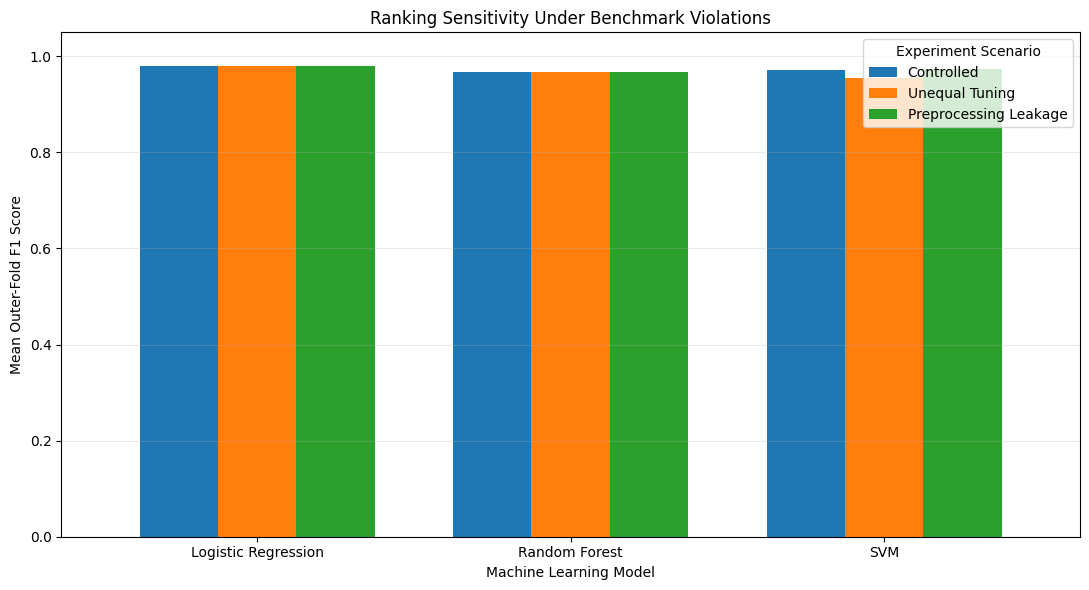

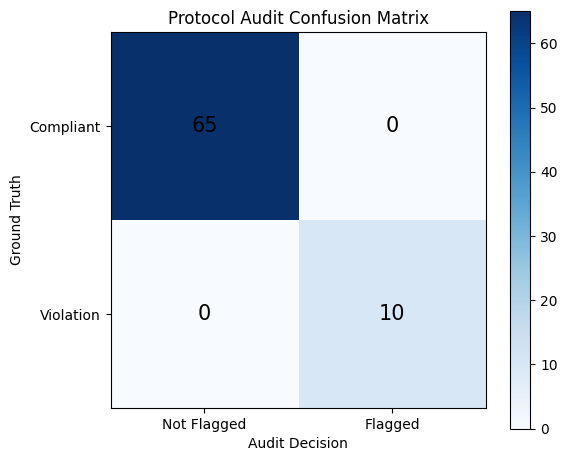

Added: benchmark_summary.csv
Added: fold_results.csv
Added: selected_hyperparameters.csv
Added: fairness_audit_report.csv
Added: unequal_tuning_results.csv
Added: preprocessing_leakage_results.csv
Added: violation_audit_details.csv
Added: ranking_comparison.csv
Added: paired_f1_differences.csv
Added: fold_ranking_changes.csv
Added: model_comparison.png
Added: ranking_sensitivity.png
Added: audit_confusion_matrix.png
Added: experiment_environment.json

Research results ZIP created successfully!


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [15]:

import matplotlib.pyplot as plt
import json
import platform
import sklearn
import zipfile
from pathlib import Path

# Chart 1: Ranking sensitivity
plot_df = comparison.pivot(
    index="model",
    columns="scenario",
    values="mean"
)

plot_df = plot_df.reindex(
    columns=[
        "Controlled",
        "Unequal Tuning",
        "Preprocessing Leakage"
    ]
)

ax = plot_df.plot(
    kind="bar",
    figsize=(11, 6),
    width=0.75
)

plt.title(
    "Ranking Sensitivity Under Benchmark Violations"
)
plt.xlabel("Machine Learning Model")
plt.ylabel("Mean Outer-Fold F1 Score")
plt.ylim(0, 1.05)
plt.xticks(rotation=0)
plt.legend(title="Experiment Scenario")
plt.grid(axis="y", alpha=0.25)
plt.tight_layout()

plt.savefig(
    "ranking_sensitivity.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


# Chart 2: Audit confusion matrix
audit_matrix = np.array([
    [tn, fp],
    [fn, tp]
])

fig, ax = plt.subplots(figsize=(6, 5))

image = ax.imshow(audit_matrix, cmap="Blues")

ax.set_xticks([0, 1])
ax.set_yticks([0, 1])

ax.set_xticklabels(["Not Flagged", "Flagged"])
ax.set_yticklabels(["Compliant", "Violation"])

ax.set_xlabel("Audit Decision")
ax.set_ylabel("Ground Truth")

for i in range(2):
    for j in range(2):
        ax.text(
            j, i,
            str(audit_matrix[i, j]),
            ha="center",
            va="center",
            fontsize=15
        )

plt.title("Protocol Audit Confusion Matrix")
plt.colorbar(image)
plt.tight_layout()

plt.savefig(
    "audit_confusion_matrix.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


# Experiment environment metadata
environment_info = {
    "project": "CrossModel BenchLab",
    "team": "Coder Girls",
    "dataset": "Breast Cancer Wisconsin Diagnostic",
    "random_seed": SEED,
    "outer_folds": 5,
    "outer_repeats": 3,
    "inner_folds": 3,
    "reference_candidate_configurations": 10,
    "diagnostic_folds": 5,
    "python_version": platform.python_version(),
    "scikit_learn_version": sklearn.__version__,
    "pandas_version": pd.__version__,
    "numpy_version": np.__version__,
    "primary_metric": "f1"
}

with open(
    "experiment_environment.json",
    "w",
    encoding="utf-8"
) as file:
    json.dump(
        environment_info,
        file,
        indent=2
    )


# Files to save for dashboard and research report
research_files = [
    "benchmark_summary.csv",
    "fold_results.csv",
    "selected_hyperparameters.csv",
    "fairness_audit_report.csv",
    "unequal_tuning_results.csv",
    "preprocessing_leakage_results.csv",
    "violation_audit_details.csv",
    "ranking_comparison.csv",
    "paired_f1_differences.csv",
    "fold_ranking_changes.csv",
    "model_comparison.png",
    "ranking_sensitivity.png",
    "audit_confusion_matrix.png",
    "experiment_environment.json"
]

# Verify before packaging
missing = [
    filename
    for filename in research_files
    if not Path(filename).exists()
]

if missing:
    raise FileNotFoundError(
        f"Missing research files: {missing}"
    )

zip_name = "CrossModel_BenchLab_Research_Results.zip"

with zipfile.ZipFile(
    zip_name,
    "w",
    zipfile.ZIP_DEFLATED
) as archive:

    for filename in research_files:
        archive.write(filename)
        print("Added:", filename)

print("\nResearch results ZIP created successfully!")

from google.colab import files

files.download(zip_name)



## Independent Holdout Evaluation

### Objective

To evaluate the final selected classifier on an independent test partition that was not used during model selection or hyperparameter tuning.

### Model Selection

The classifier family is selected according to the highest mean outer-fold F1-score from the controlled nested cross-validation experiment.

### Final Training

The selected classifier undergoes a final three-fold GridSearchCV using only the development partition and its original 10 candidate hyperparameter configurations.

### Independent Evaluation

The fitted model is evaluated once on the reserved 20% test partition.

The following metrics are recorded:

- Accuracy
- Precision
- Recall
- F1-score
- ROC-AUC
- Confusion matrix

This holdout evaluation is separate from the protocol violation experiments.

The dataset is used exclusively for benchmarking research. The resulting models are not intended for medical diagnosis or clinical decision-making.


Selected model: Logistic Regression

=== INDEPENDENT HOLDOUT RESULTS ===
{
  "selected_model": "Logistic Regression",
  "test_samples": 114,
  "accuracy": 0.9736842105263158,
  "precision": 0.9726027397260274,
  "recall": 0.9861111111111112,
  "f1": 0.9793103448275862,
  "roc_auc": 0.9957010582010581,
  "final_training_seconds": 0.4265333359999204,
  "best_parameters": {
    "model__C": 0.1
  }
}


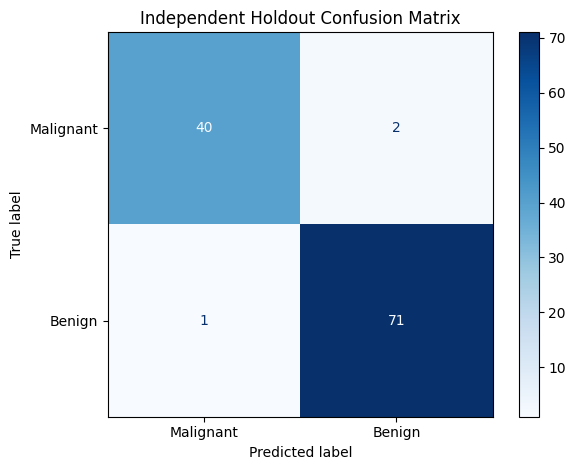


Independent evaluation completed!


In [17]:

from sklearn.base import clone
from sklearn.model_selection import (
    GridSearchCV,
    StratifiedKFold
)
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    ConfusionMatrixDisplay
)

import pandas as pd
import matplotlib.pyplot as plt
import json
import time

selected_model_name = summary_df.index[0]

print("Selected model:", selected_model_name)


final_cv = StratifiedKFold(
    n_splits=3,
    shuffle=True,
    random_state=SEED
)

final_search = GridSearchCV(
    estimator=clone(models[selected_model_name]),
    param_grid=param_grids[selected_model_name],
    scoring="f1",
    cv=final_cv,
    n_jobs=-1,
    refit=True,
    error_score="raise"
)

start = time.perf_counter()

final_search.fit(X_dev, y_dev)

final_training_time = time.perf_counter() - start

final_model = final_search.best_estimator_


y_test_pred = final_model.predict(X_test)

if hasattr(final_model, "decision_function"):
    y_test_score = final_model.decision_function(X_test)
else:
    y_test_score = final_model.predict_proba(X_test)[:, 1]

holdout_metrics = {
    "selected_model": selected_model_name,
    "test_samples": len(X_test),
    "accuracy": float(
        accuracy_score(y_test, y_test_pred)
    ),
    "precision": float(
        precision_score(
            y_test, y_test_pred, zero_division=0
        )
    ),
    "recall": float(
        recall_score(
            y_test, y_test_pred, zero_division=0
        )
    ),
    "f1": float(
        f1_score(
            y_test, y_test_pred, zero_division=0
        )
    ),
    "roc_auc": float(
        roc_auc_score(y_test, y_test_score)
    ),
    "final_training_seconds": float(
        final_training_time
    ),
    "best_parameters": final_search.best_params_
}

print("\n=== INDEPENDENT HOLDOUT RESULTS ===")
print(json.dumps(holdout_metrics, indent=2))


with open(
    "holdout_metrics.json", "w", encoding="utf-8"
) as f:
    json.dump(holdout_metrics, f, indent=2)

pd.DataFrame([{
    k: v for k, v in holdout_metrics.items()
    if k != "best_parameters"
}]).to_csv(
    "holdout_results.csv",
    index=False
)


cm = confusion_matrix(
    y_test,
    y_test_pred,
    labels=[0, 1]
)

display_plot = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Malignant", "Benign"]
)

display_plot.plot(cmap="Blues")
plt.title("Independent Holdout Confusion Matrix")
plt.tight_layout()
plt.savefig(
    "holdout_confusion_matrix.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

print("\nIndependent evaluation completed!")


## Experimental Results Validation

In [18]:

from pathlib import Path
import pandas as pd

required_files = [
    "benchmark_summary.csv",
    "fold_results.csv",
    "fairness_audit_report.csv",
    "violation_audit_details.csv",
    "ranking_comparison.csv",
    "paired_f1_differences.csv",
    "fold_ranking_changes.csv",
    "holdout_results.csv",
    "holdout_metrics.json",
    "experiment_environment.json"
]

print("=== FILE VALIDATION ===")

missing = []

for filename in required_files:
    path = Path(filename)

    if path.exists() and path.stat().st_size > 0:
        print("PASS:", filename)
    else:
        print("MISSING:", filename)
        missing.append(filename)

assert not missing, f"Missing files: {missing}"

fold_data = pd.read_csv("fold_results.csv")
audit_data = pd.read_csv("fairness_audit_report.csv")
ranking_data = pd.read_csv("ranking_comparison.csv")

assert len(fold_data) == 45
assert len(audit_data) == 90
assert fold_data["model"].nunique() == 3

expected_scenarios = {
    "Controlled",
    "Unequal Tuning",
    "Preprocessing Leakage"
}

assert set(ranking_data["scenario"]) == expected_scenarios

print("\nAll essential research files validated!")


=== FILE VALIDATION ===
PASS: benchmark_summary.csv
PASS: fold_results.csv
PASS: fairness_audit_report.csv
PASS: violation_audit_details.csv
PASS: ranking_comparison.csv
PASS: paired_f1_differences.csv
PASS: fold_ranking_changes.csv
PASS: holdout_results.csv
PASS: holdout_metrics.json
PASS: experiment_environment.json

All essential research files validated!


In [19]:

%%writefile requirements.txt
streamlit>=1.35,<2
pandas>=2.2,<3
numpy>=1.26,<3
plotly>=5.20,<7
scikit-learn>=1.5,<2
matplotlib>=3.8,<4


Writing requirements.txt


In [20]:

import subprocess

with open("experiment_requirements.txt", "w") as f:
    subprocess.run(
        ["python", "-m", "pip", "freeze"],
        stdout=f,
        check=True
    )

print("Experiment dependencies saved.")


Experiment dependencies saved.



## Interactive Research Dashboard

CrossModel BenchLab includes an interactive Streamlit application for inspecting benchmarking results.

### Main Features

1. Overview of the controlled benchmark
2. Model performance comparisons
3. Recorded protocol audit results
4. Intentional violation detection analysis
5. Ranking sensitivity visualization
6. Independent holdout evaluation
7. Research evidence and file downloads

### Data Integrity

The application reads saved experimental outputs. It does not generate artificial research metrics. The dashboard distinguishes controlled reference experiments, diagnostic protocol violations and independent holdout results. Audit status describes verification of recorded protocol controls and does not establish universal benchmarking fairness.


In [21]:

%%writefile app.py
import json
from pathlib import Path

import pandas as pd
import plotly.express as px
import streamlit as st

BASE = Path(__file__).resolve().parent
RESULTS = BASE / "results"

st.set_page_config(
    page_title="CrossModel BenchLab",
    page_icon="🔬",
    layout="wide"
)

st.markdown("""
<style>
.block-container {
    padding-top: 2rem;
    padding-bottom: 3rem;
}
h1, h2, h3 { letter-spacing: -0.02em; }
[data-testid="stMetric"] {
    border: 1px solid rgba(128,128,128,.22);
    border-radius: 12px;
    padding: 14px;
}
</style>
""", unsafe_allow_html=True)


@st.cache_data
def load_csv(filename):
    path = RESULTS / filename
    if not path.exists():
        return None
    return pd.read_csv(path)


@st.cache_data
def load_json(filename):
    path = RESULTS / filename
    if not path.exists():
        return None
    with open(path, encoding="utf-8") as f:
        return json.load(f)


folds = load_csv("fold_results.csv")
summary = load_csv("benchmark_summary.csv")
audit = load_csv("fairness_audit_report.csv")
diagnostics = load_csv("violation_audit_details.csv")
ranking = load_csv("ranking_comparison.csv")
paired = load_csv("paired_f1_differences.csv")
changes = load_csv("fold_ranking_changes.csv")
holdout = load_json("holdout_metrics.json")
environment = load_json("experiment_environment.json")

st.title("🔬 CrossModel BenchLab")
st.caption(
    "An Auditable Framework for Fair, Reproducible "
    "and Cost-Aware Machine Learning Benchmarking"
)
st.markdown(
    "**Team Coder Girls** | Track 5 — Research & "
    "Publications | Challenge 06"
)

st.sidebar.title("Research Navigation")

page = st.sidebar.radio(
    "Select Section",
    [
        "Overview",
        "Model Comparison",
        "Fairness Audit",
        "Violation Experiments",
        "Ranking Sensitivity",
        "Independent Holdout Test",
        "Research Evidence"
    ]
)

st.sidebar.divider()
st.sidebar.caption(
    "Dataset: Breast Cancer Wisconsin (Diagnostic)"
)
st.sidebar.caption(
    "Audit is based on recorded protocol evidence."
)


if page == "Overview":
    st.header("Research Overview")

    st.write(
        "CrossModel BenchLab evaluates whether "
        "machine learning classifiers are compared "
        "under consistent and reproducible conditions."
    )

    if folds is not None:
        c1, c2, c3, c4 = st.columns(4)

        c1.metric("Models", folds["model"].nunique())
        c2.metric("Outer Evaluations", len(folds))
        c3.metric(
            "Mean F1",
            f"{folds['f1'].mean():.4f}"
        )
        c4.metric(
            "Baseline Audit Checks",
            len(audit) if audit is not None else "N/A"
        )

        st.subheader("F1 Distribution")

        fig = px.box(
            folds,
            x="model",
            y="f1",
            color="model",
            points="all"
        )
        st.plotly_chart(fig, use_container_width=True)

        st.info(
            "The mean F1 metric above is pooled across "
            "controlled outer-fold evaluations. "
            "It is not the independent holdout result."
        )
    else:
        st.error("fold_results.csv not found.")


elif page == "Model Comparison":
    st.header("Controlled Model Comparison")

    if folds is not None:
        metric = st.selectbox(
            "Evaluation Metric",
            [
                "f1",
                "accuracy",
                "precision",
                "recall",
                "roc_auc",
                "train_seconds",
                "inference_ms_per_sample",
                "model_size_kb"
            ]
        )

        table = (
            folds.groupby("model")[metric]
            .agg(["mean", "std", "count"])
            .reset_index()
        )

        st.dataframe(
            table.round(5),
            use_container_width=True
        )

        fig = px.bar(
            table,
            x="model",
            y="mean",
            error_y="std",
            color="model",
            title=f"Mean {metric} by Model"
        )
        st.plotly_chart(fig, use_container_width=True)

        st.subheader("Fold-Level Results")
        st.dataframe(
            folds.round(5),
            use_container_width=True
        )
    else:
        st.error("Model comparison data unavailable.")


elif page == "Fairness Audit":
    st.header("Benchmark Fairness Audit")

    st.write(
        "The audit checks recorded experimental "
        "metadata against specified protocol rules."
    )

    if audit is not None:
        counts = audit["status"].value_counts()

        c1, c2, c3 = st.columns(3)
        for col, label in zip(
            [c1, c2, c3],
            ["PASS", "FLAGGED", "NOT VERIFIABLE"]
        ):
            col.metric(label, int(counts.get(label, 0)))

        st.dataframe(
            audit,
            use_container_width=True
        )

        fig = px.histogram(
            audit,
            x="check",
            color="status",
            barmode="group",
            title="Protocol Audit Status by Check"
        )
        st.plotly_chart(fig, use_container_width=True)

        st.warning(
            "PASS means the recorded evidence satisfies "
            "the specified rule. It does not prove that "
            "hidden implementation errors are absent."
        )
    else:
        st.error("Fairness audit file unavailable.")


elif page == "Violation Experiments":
    st.header("Intentional Violation Experiments")

    if diagnostics is not None:
        st.dataframe(
            diagnostics,
            use_container_width=True
        )

        valid = diagnostics[
            diagnostics["status"] != "NOT VERIFIABLE"
        ].copy()

        truth = valid["expected_violation"].astype(bool)
        detected = valid["status"].eq("FLAGGED")

        tp = int((truth & detected).sum())
        fp = int((~truth & detected).sum())

        fn = int((
            diagnostics["expected_violation"].astype(bool)
            & diagnostics["status"].ne("FLAGGED")
        ).sum())

        tn = int((~truth & ~detected).sum())

        rate = (
            tp / (tp + fn)
            if tp + fn else None
        )

        c1, c2, c3, c4 = st.columns(4)
        c1.metric("True Positives", tp)
        c2.metric("False Positives", fp)
        c3.metric("False Negatives", fn)
        c4.metric(
            "Detection Rate",
            f"{rate:.1%}" if rate is not None else "N/A"
        )

        figure = px.histogram(
            diagnostics,
            x="scenario",
            color="status",
            barmode="group",
            title="Audit Outcomes by Scenario"
        )
        st.plotly_chart(
            figure,
            use_container_width=True
        )

        st.info(
            "Detection rate applies only to the "
            "documented injected protocol violations."
        )
    else:
        st.error("Diagnostic audit results unavailable.")


elif page == "Ranking Sensitivity":
    st.header("Model Ranking Sensitivity")

    if ranking is not None:
        st.dataframe(
            ranking.round(5),
            use_container_width=True
        )

        fig = px.bar(
            ranking,
            x="model",
            y="mean",
            color="scenario",
            barmode="group",
            title="Mean F1 Under Different Protocols"
        )
        st.plotly_chart(
            fig,
            use_container_width=True
        )

        if paired is not None:
            st.subheader("Paired SVM F1 Differences")
            st.dataframe(
                paired.round(5),
                use_container_width=True
            )

            shift = px.box(
                paired,
                x="scenario",
                y="delta_f1",
                color="scenario",
                points="all"
            )
            st.plotly_chart(
                shift,
                use_container_width=True
            )

        if changes is not None:
            st.subheader("Fold-Level Ranking Changes")
            st.dataframe(
                changes,
                use_container_width=True
            )

        st.caption(
            "Only SVM is modified in diagnostic "
            "scenarios. LR and RF remain at reference "
            "conditions. The results are exploratory."
        )
    else:
        st.error("Ranking results unavailable.")


elif page == "Independent Holdout Test":
    st.header("Independent Holdout Evaluation")

    if holdout is not None:
        st.success(
            "Selected model: "
            + str(holdout["selected_model"])
        )

        c1, c2, c3 = st.columns(3)

        c1.metric(
            "Test F1",
            f"{holdout['f1']:.4f}"
        )
        c2.metric(
            "Test Accuracy",
            f"{holdout['accuracy']:.4f}"
        )
        c3.metric(
            "Test ROC-AUC",
            f"{holdout['roc_auc']:.4f}"
        )

        metric_names = [
            "accuracy", "precision",
            "recall", "f1", "roc_auc"
        ]

        metrics = pd.DataFrame({
            "Metric": metric_names,
            "Value": [
                holdout[key] for key in metric_names
            ]
        })

        st.dataframe(
            metrics,
            use_container_width=True
        )

        image_path = (
            RESULTS / "holdout_confusion_matrix.png"
        )

        if image_path.exists():
            st.image(
                str(image_path),
                caption="Independent Holdout Confusion Matrix"
            )

        st.info(
            "The holdout partition was not used "
            "during model selection or diagnostic "
            "protocol violation experiments. "
            "Positive class 1 represents benign cases."
        )
    else:
        st.error("Holdout metrics unavailable.")


elif page == "Research Evidence":
    st.header("Research Evidence")

    st.write(
        "Download the experimental records and "
        "inspect the reproducibility metadata."
    )

    if environment is not None:
        st.subheader("Experiment Environment")
        st.json(environment)

    available = sorted(RESULTS.glob("*"))

    if not available:
        st.warning("No research evidence files found.")

    for path in available:
        if path.is_file():
            st.download_button(
                label=f"Download {path.name}",
                data=path.read_bytes(),
                file_name=path.name,
                mime="application/octet-stream",
                key=path.name
            )

    st.divider()
    st.subheader("Research Limitations")

    st.markdown("""
- One public dataset and three classifier families.
- Two deliberately altered SVM conditions.
- Metadata-based checks cannot detect every hidden error.
- Diagnostic results use five outer folds.
- Repeated folds are not independent observations.
- Equal configuration counts do not imply equal compute.
- Holdout results are not a clinical validation.
""")

    st.subheader("Development Attribution")
    st.write(
        "AI-assisted coding and documentation were "
        "used during development. The team is "
        "responsible for reviewing, testing and "
        "explaining the submitted work."
    )

st.divider()
st.caption(
    "CrossModel BenchLab | Team Coder Girls | "
    "Research prototype — not a medical device"
)


Writing app.py


## Project Documentation and Research Reporting

The final project repository contains documentation supporting independent review and reproduction of the experiments.


In [22]:

from pathlib import Path
import pandas as pd
import numpy as np
import json

Path("docs").mkdir(exist_ok=True)

required_files = [
    "fold_results.csv",
    "ranking_comparison.csv",
    "violation_audit_details.csv",
    "holdout_metrics.json"
]

for filename in required_files:
    path = Path(filename)
    assert path.exists(), f"Missing file: {filename}"
    print("PASS:", filename)

print("\nDocumentation setup ready!")


PASS: fold_results.csv
PASS: ranking_comparison.csv
PASS: violation_audit_details.csv
PASS: holdout_metrics.json

Documentation setup ready!


In [23]:

fold_data = pd.read_csv("fold_results.csv")
ranking_data = pd.read_csv("ranking_comparison.csv")
violation_data = pd.read_csv(
    "violation_audit_details.csv"
)

with open("holdout_metrics.json", encoding="utf-8") as f:
    holdout_info = json.load(f)

model_summary = (
    fold_data.groupby("model")["f1"]
    .agg(["mean", "std", "count"])
    .sort_values("mean", ascending=False)
)


def to_boolean(series):
    return series.astype(str).str.lower().eq("true")

truth = to_boolean(
    violation_data["expected_violation"]
)
flagged = violation_data["status"].eq("FLAGGED")
verifiable = violation_data["status"].ne(
    "NOT VERIFIABLE"
)

TP = int((truth & flagged).sum())
FN = int((truth & ~flagged).sum())
FP = int((~truth & flagged & verifiable).sum())
TN = int((~truth & ~flagged & verifiable).sum())

detection_rate = (
    TP / (TP + FN)
    if TP + FN > 0 else float("nan")
)

model_rows = "\n".join(
    f"| {name} | {row['mean']:.4f} | "
    f"{row['std']:.4f} | {int(row['count'])} |"
    for name, row in model_summary.iterrows()
)

rank_lines = []

for scenario, group in ranking_data.groupby("scenario"):
    ordered = group.sort_values(
        ["mean", "model"],
        ascending=[False, True]
    )
    rank_lines.append(
        f"- **{scenario}:** "
        + " > ".join(ordered["model"].tolist())
    )

ranking_text = "\n".join(rank_lines)

print("=== Controlled Benchmark ===")
display(model_summary.round(4))

print("\n=== Audit Results ===")
print("TP:", TP, "FN:", FN, "FP:", FP, "TN:", TN)
print("Detection Rate:", f"{detection_rate:.2%}")

print("\n=== Holdout Results ===")
print("Model:", holdout_info["selected_model"])
print("F1:", holdout_info["f1"])


=== Controlled Benchmark ===


,mean,std,count
model,,,
Logistic Regression,0.9815,0.0078,15
SVM,0.9749,0.0087,15
Random Forest,0.9685,0.0111,15



=== Audit Results ===
TP: 10 FN: 0 FP: 0 TN: 65
Detection Rate: 100.00%

=== Holdout Results ===
Model: Logistic Regression
F1: 0.9793103448275862


In [24]:

methodology = """# Research Methodology

## Project Information

Project: CrossModel BenchLab

Team: Coder Girls

Track: Research & Publications
Challenge: CrossModel — Benchmarking Multiple Models Fairly

## Dataset

Breast Cancer Wisconsin (Diagnostic)

- 569 samples
- 30 numerical input features
- Binary classification
- Class 0: Malignant
- Class 1: Benign

Dataset source:
https://archive.ics.uci.edu/dataset/17/breast+cancer+wisconsin+diagnostic

## Data Partitioning

An 80/20 stratified split divides the data into
development and independent holdout partitions.

The independent test data is reserved for evaluation
after model-family selection and final tuning.

## Machine Learning Models

1. Logistic Regression
2. Random Forest
3. Support Vector Machine

## Nested Cross Validation

- Five outer stratified folds
- Three outer repeats
- Three inner stratified folds
- Ten candidate configurations per model
- Primary scoring metric: F1-score
- Fixed random seeds
- Identical outer partitions for all models

Logistic Regression and SVM use StandardScaler
inside model pipelines.

## Fairness Audit

The baseline audit examines recorded information
about:

- Partition signatures
- Preprocessing pipeline metadata
- Hyperparameter tuning counts
- Random seed records
- Scoring metric
- Environment metadata availability

Audit decisions include PASS, FLAGGED
and NOT VERIFIABLE.

A metadata PASS does not independently prove
the absence of hidden implementation problems.

## Diagnostic Protocol Violations

Two deliberate SVM experiments were conducted
using the first five outer folds.

### Experiment A: Unequal Tuning

Reduce the SVM tuning budget from ten candidate
configurations to two.

### Experiment B: Preprocessing Leakage

Fit the StandardScaler on the entire development
partition before cross-validation.

This deliberately introduces validation information
into preprocessing.

The independent holdout partition is excluded.

## Research Questions

RQ1: Can specified metadata audit checks detect
the injected protocol inconsistencies?

RQ2: How do the inconsistencies affect F1-score
and model rankings?

## Independent Holdout

The selected model family is chosen using
controlled nested cross-validation results.

A final three-fold GridSearchCV is fitted on
development data only.

The selected estimator is evaluated once on
the independent holdout partition.

## Limitations

- One public dataset
- Three classifier families
- Two altered SVM scenarios
- Five diagnostic outer folds
- Metadata-based checks
- Repeated folds are correlated
- Equal candidate counts do not guarantee
  equal computational effort

This project is a benchmarking research prototype,
not a clinical diagnostic system.
"""

Path("docs/methodology.md").write_text(
    methodology,
    encoding="utf-8"
)

print("PASS: methodology.md created")


PASS: methodology.md created


In [25]:

findings = f"""# Research Findings

## CrossModel BenchLab

Team Coder Girls

## Controlled Benchmark

| Model | Mean F1 | Standard Deviation | Evaluations |
|---|---:|---:|---:|
{model_rows}

These values are computed from the controlled
nested cross-validation results.

## RQ1: Audit Detection

- True Positives: {TP}
- False Negatives: {FN}
- False Positives: {FP}
- True Negatives: {TN}
- Detection Rate: {detection_rate:.2%}

This rate applies only to the documented
injected protocol deviations.

## RQ2: Ranking Sensitivity

{ranking_text}

See these output files for more information:

- ranking_comparison.csv
- paired_f1_differences.csv
- fold_ranking_changes.csv

## Independent Holdout Evaluation

- Selected Model: {holdout_info['selected_model']}
- Test Samples: {holdout_info['test_samples']}
- Accuracy: {holdout_info['accuracy']:.4f}
- Precision: {holdout_info['precision']:.4f}
- Recall: {holdout_info['recall']:.4f}
- F1-score: {holdout_info['f1']:.4f}
- ROC-AUC: {holdout_info['roc_auc']:.4f}

The positive class (1) represents benign cases.

## Interpretation

The results illustrate the performance and
audit outcomes observed under the tested
benchmark protocols.

An injected protocol violation need not
produce a measurable ranking change.

## Limitations

These results are limited to one public dataset,
three classifier families and two deliberately
altered SVM scenarios.

The metadata audit does not detect every possible
form of data leakage or implementation error.
"""

Path("docs/research_findings.md").write_text(
    findings,
    encoding="utf-8"
)

print("PASS: research_findings.md created")


PASS: research_findings.md created


In [26]:

readme = f"""# CrossModel BenchLab

### An Auditable Framework for Fair, Reproducible and Cost-Aware Machine Learning Benchmarking

**Team:** Coder Girls

**Hackathon:** AI Innovation Hackathon 2026

**Track:** 5 — Research & Publications

**Challenge:** 06 — CrossModel

## Team Members

- Nusrat Bhuiyan Nowrin
- Tania Tun Jannat

## Project Overview

CrossModel BenchLab is an experimental framework
for comparing classification models under documented
and reproducible benchmarking conditions.

It combines nested cross-validation,
protocol metadata checks, intentional violation
experiments and ranking sensitivity analysis.

## Research Questions

**RQ1:** Can automated audit rules detect
intentional protocol inconsistencies?

**RQ2:** Do the inconsistencies change
measured model performance or rankings?

## Dataset

Breast Cancer Wisconsin (Diagnostic)

- 569 samples
- 30 features
- Two diagnostic classes

Source:
https://archive.ics.uci.edu/dataset/17/breast+cancer+wisconsin+diagnostic

## Models

1. Logistic Regression
2. Random Forest
3. Support Vector Machine

## Evaluation Protocol

- 80/20 stratified development/test split
- Five outer folds repeated three times
- Three inner folds
- Ten hyperparameter candidates per model
- Primary metric: F1-score
- Fixed random seeds and shared outer partitions

## Controlled Benchmark Results

| Model | Mean F1 | Standard Deviation | Evaluations |
|---|---:|---:|---:|
{model_rows}

## Fairness Audit

The metadata-based audit examines documented
partition consistency, preprocessing records,
tuning budgets, random seeds, metrics
and environment information.

Audit statuses:

- PASS
- FLAGGED
- NOT VERIFIABLE

## Intentional Violation Experiments

Two SVM diagnostic scenarios:

1. Unequal tuning budget: 10 to 2 configurations
2. Preprocessing leakage using full development data

The independent holdout partition was excluded
from both diagnostic conditions.

## RQ1: Audit Detection Results

- True Positives: {TP}
- False Negatives: {FN}
- False Positives: {FP}
- True Negatives: {TN}
- Detection Rate: {detection_rate:.2%}

These measurements describe the injected test cases,
not general-purpose leakage detection capability.

## RQ2: Ranking Sensitivity

{ranking_text}

Full numerical outputs are available in results/.

## Independent Holdout Results

- Selected Model: {holdout_info['selected_model']}
- Test Samples: {holdout_info['test_samples']}
- F1: {holdout_info['f1']:.4f}
- Accuracy: {holdout_info['accuracy']:.4f}
- ROC-AUC: {holdout_info['roc_auc']:.4f}

The positive class represents benign observations.
The benchmark is not intended for medical diagnosis.

## Technology Stack

Python, scikit-learn, pandas, NumPy,
Matplotlib, Plotly, Streamlit and Google Colab.

## Run the Dashboard

Install dependencies:

```bash
pip install -r requirements.txt
```

Start Streamlit:

```bash
streamlit run app.py
```

The application loads saved data from results/.

## Repository Contents

- app.py — Streamlit application
- requirements.txt — Dashboard dependencies
- README.md — Project documentation
- results/ — Experiment CSVs, JSON and charts
- docs/methodology.md — Research method
- docs/research_findings.md — Actual findings
- CrossModel_BenchLab_Coder_Girls.ipynb —
  Experiment notebook (upload separately)

## Reproducibility

Open the supplied Google Colab notebook and
run the cells sequentially.

The recorded environment information and
experimental outputs are provided in results/.

## Limitations

- One public dataset and three classifier families
- Two diagnostic SVM protocol modifications
- Five folds for diagnostic comparisons
- Metadata audits cannot prove the absence of
  hidden code-level implementation errors
- Equal parameter counts do not imply equal compute
- Repeated folds are statistically correlated

## Future Work

- Additional public datasets
- More classifier families
- Code-level provenance verification
- Wider violation-injection experiments
- Hardware-aware computational budgets

## Development Attribution

ChatGPT was used to assist with code drafting,
debugging guidance, documentation and dashboard
development. Experimental results were generated
by executing the supplied research workflow.

## References

- UCI Machine Learning Repository
- scikit-learn documentation
- Streamlit documentation
- Related research described in the Stage 1 proposal
"""

Path("README.md").write_text(
    readme,
    encoding="utf-8"
)

print("PASS: README.md created")


PASS: README.md created


In [27]:

documentation_files = [
    "README.md",
    "docs/methodology.md",
    "docs/research_findings.md"
]

for filename in documentation_files:
    path = Path(filename)

    assert path.exists(), f"Missing: {filename}"
    assert path.stat().st_size > 0

    print("PASS:", filename)

print("\nCELL 18 COMPLETED!")


PASS: README.md
PASS: docs/methodology.md
PASS: docs/research_findings.md

CELL 18 COMPLETED!


In [28]:

from pathlib import Path
import shutil

project = Path("/content/CrossModel_BenchLab_Final")

# Recreate final folder to prevent stale files
if project.exists():
    shutil.rmtree(project)

project.mkdir(parents=True)
(project / "results").mkdir()
(project / "docs").mkdir()

print("PASS: Final project folders created")


PASS: Final project folders created


In [29]:

main_files = [
    "app.py",
    "requirements.txt",
    "README.md"
]

# Optional environment record, created in Cell 16
if Path("experiment_requirements.txt").exists():
    main_files.append("experiment_requirements.txt")

for filename in main_files:
    source = Path("/content") / filename

    assert source.exists(), f"Missing: {filename}"

    shutil.copy2(
        source,
        project / filename
    )

    print("Copied:", filename)


Copied: app.py
Copied: requirements.txt
Copied: README.md
Copied: experiment_requirements.txt


In [30]:

research_files = [
    "benchmark_summary.csv",
    "fold_results.csv",
    "selected_hyperparameters.csv",
    "fairness_audit_report.csv",
    "unequal_tuning_results.csv",
    "preprocessing_leakage_results.csv",
    "violation_audit_details.csv",
    "ranking_comparison.csv",
    "paired_f1_differences.csv",
    "fold_ranking_changes.csv",
    "holdout_results.csv",
    "holdout_metrics.json",
    "experiment_environment.json",
    "model_comparison.png",
    "ranking_sensitivity.png",
    "audit_confusion_matrix.png",
    "holdout_confusion_matrix.png"
]

for filename in research_files:
    source = Path("/content") / filename

    assert source.exists(), f"Missing: {filename}"

    shutil.copy2(
        source,
        project / "results" / filename
    )

    print("Copied:", filename)

print("\nResearch files:", len(research_files))


Copied: benchmark_summary.csv
Copied: fold_results.csv
Copied: selected_hyperparameters.csv
Copied: fairness_audit_report.csv
Copied: unequal_tuning_results.csv
Copied: preprocessing_leakage_results.csv
Copied: violation_audit_details.csv
Copied: ranking_comparison.csv
Copied: paired_f1_differences.csv
Copied: fold_ranking_changes.csv
Copied: holdout_results.csv
Copied: holdout_metrics.json
Copied: experiment_environment.json
Copied: model_comparison.png
Copied: ranking_sensitivity.png
Copied: audit_confusion_matrix.png
Copied: holdout_confusion_matrix.png

Research files: 17


In [31]:

docs_files = [
    "methodology.md",
    "research_findings.md"
]

for filename in docs_files:
    source = Path("/content/docs") / filename

    assert source.exists(), f"Missing: {filename}"

    shutil.copy2(
        source,
        project / "docs" / filename
    )

    print("Copied:", filename)

print("\nOnly the two requested docs were added.")


Copied: methodology.md
Copied: research_findings.md

Only the two requested docs were added.


In [32]:

import zipfile
from google.colab import files

zip_path = Path(
    "/content/CrossModel_BenchLab_Final.zip"
)

# Recreate ZIP
if zip_path.exists():
    zip_path.unlink()

with zipfile.ZipFile(
    zip_path,
    mode="w",
    compression=zipfile.ZIP_DEFLATED
) as archive:

    for path in sorted(project.rglob("*")):
        if path.is_file():
            archive.write(
                path,
                arcname=path.relative_to(project)
            )

print("Final ZIP:", zip_path)
print("Size:", round(zip_path.stat().st_size / 1024, 2), "KB")

files.download(str(zip_path))


Final ZIP: /content/CrossModel_BenchLab_Final.zip
Size: 332.2 KB


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [33]:
# Final Application Validation

import py_compile
import zipfile
from pathlib import Path
import pandas as pd
import json

project = Path("/content/CrossModel_BenchLab_Final")

# Test Python syntax
py_compile.compile(
    str(project / "app.py"),
    doraise=True
)

print("PASS: app.py syntax")

# Check required project files
must_exist = [
    "app.py",
    "requirements.txt",
    "README.md",
    "docs/methodology.md",
    "docs/research_findings.md",
    "results/fold_results.csv",
    "results/benchmark_summary.csv",
    "results/fairness_audit_report.csv",
    "results/violation_audit_details.csv",
    "results/ranking_comparison.csv",
    "results/holdout_metrics.json"
]

for filename in must_exist:
    path = project / filename
    assert path.exists(), f"Missing: {filename}"
    print("PASS:", filename)

# Check result structure
folds = pd.read_csv(
    project / "results/fold_results.csv"
)

assert len(folds) == 45
assert folds["model"].nunique() == 3

with open(
    project / "results/holdout_metrics.json",
    encoding="utf-8"
) as f:
    holdout = json.load(f)

assert holdout["test_samples"] == 114

# Verify no separate AI disclosure file
assert not (
    project / "docs/ai_assistance_disclosure.md"
).exists()

# Verify downloaded ZIP contents
zip_path = Path(
    "/content/CrossModel_BenchLab_Final.zip"
)

assert zip_path.exists()

with zipfile.ZipFile(zip_path) as archive:
    assert archive.testzip() is None
    names = archive.namelist()
    assert "app.py" in names
    assert "README.md" in names

print("\nFINAL FILE VALIDATION PASSED!")


PASS: app.py syntax
PASS: app.py
PASS: requirements.txt
PASS: README.md
PASS: docs/methodology.md
PASS: docs/research_findings.md
PASS: results/fold_results.csv
PASS: results/benchmark_summary.csv
PASS: results/fairness_audit_report.csv
PASS: results/violation_audit_details.csv
PASS: results/ranking_comparison.csv
PASS: results/holdout_metrics.json

FINAL FILE VALIDATION PASSED!


In [34]:

!pip -q install -r /content/CrossModel_BenchLab_Final/requirements.txt


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 10.4/10.4 MB 55.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 11.4/11.4 MB 54.4 MB/s eta 0:00:00


In [36]:

from pathlib import Path

log_path = Path("/content/crossmodel_streamlit.log")

if log_path.exists():
    print(log_path.read_text()[-6000:])
else:
    print("No Streamlit log found.")




2026-10-20 09:53:33.124 Uvicorn server started on 0.0.0.0:8502

  You can now view your Streamlit app in your browser.

  Local URL: http://localhost:8502
  Network URL: http://172.28.0.12:8502
  External URL: http://34.136.6.91:8502




In [38]:

import subprocess
import time
import requests
from pathlib import Path

APP = "/content/CrossModel_BenchLab_Final/app.py"
PORT = 8502
LOG = "/content/crossmodel_streamlit.log"

assert Path(APP).exists(), "app.py file missing!"

# Stop previous server process from this notebook, if any
if "server" in globals() and server.poll() is None:
    server.terminate()
    try:
        server.wait(timeout=5)
    except subprocess.TimeoutExpired:
        server.kill()
        server.wait()

# Start Streamlit server
with open(LOG, "w") as log:
    server = subprocess.Popen(
        [
            "python", "-m", "streamlit",
            "run", APP,
            f"--server.port={PORT}",
            "--server.address=0.0.0.0",
            "--server.headless=true",
            "--server.enableCORS=false",
            "--server.enableXsrfProtection=false"
        ],
        stdout=log,
        stderr=subprocess.STDOUT
    )

print("Starting Streamlit server...")

server_ready = False

for attempt in range(20):
    time.sleep(2)

    if server.poll() is not None:
        print("Server exited during startup.")
        break

    try:
        response = requests.get(
            f"http://127.0.0.1:{PORT}/_stcore/health",
            timeout=3
        )

        if response.status_code == 200:
            server_ready = True
            print("Streamlit server started!")
            print("HTTP Status:", response.status_code)
            break

    except requests.exceptions.RequestException:
        pass

if not server_ready:
    print("\n Streamlit did not become ready.")
    print("\n=== ERROR LOG ===")

    if Path(LOG).exists():
        print(Path(LOG).read_text()[-6000:])
else:
    print("\nReady for Cloudflare tunnel.")


Starting Streamlit server...
Streamlit server started!
HTTP Status: 200

Ready for Cloudflare tunnel.


In [39]:

import subprocess
import re
import time
from pathlib import Path

cloudflared = Path("/tmp/cloudflared")

if not cloudflared.exists():
    subprocess.run([
        "wget", "-q",
        "https://github.com/cloudflare/cloudflared/releases/latest/download/cloudflared-linux-amd64",
        "-O", str(cloudflared)
    ], check=True)
    cloudflared.chmod(0o755)

log_path = Path("/content/crossmodel_tunnel.log")

with open(log_path, "w") as log:
    tunnel = subprocess.Popen(
        [
            str(cloudflared),
            "tunnel",
            "--url", "http://127.0.0.1:8502",
            "--no-autoupdate"
        ],
        stdout=log,
        stderr=subprocess.STDOUT
    )

print("Creating public dashboard link...")

for attempt in range(15):
    time.sleep(2)

    logs = log_path.read_text()

    links = re.findall(
        r"https://[a-zA-Z0-9-]+\.trycloudflare\.com",
        logs
    )

    if links:
        print("\n Dashboard URL:")
        print(links[0])
        break
else:
    print("\nTunnel not ready.")
    print(log_path.read_text()[-3000:])


Creating public dashboard link...

 Dashboard URL:
https://roster-spy-centers-oakland.trycloudflare.com
